In [ ]:
import pandas as pd
df = pd.read_csv("olist_customers_dataset.csv")
print(df.shape)
df.info()
missing = df.isnull().sum()
print((missing/len(df)) * 100)
df.head()

(99441, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
df = df.drop(columns=['customer_zip_code_prefix', 'customer_unique_id'])
df.head()

,customer_id,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,campinas,SP


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


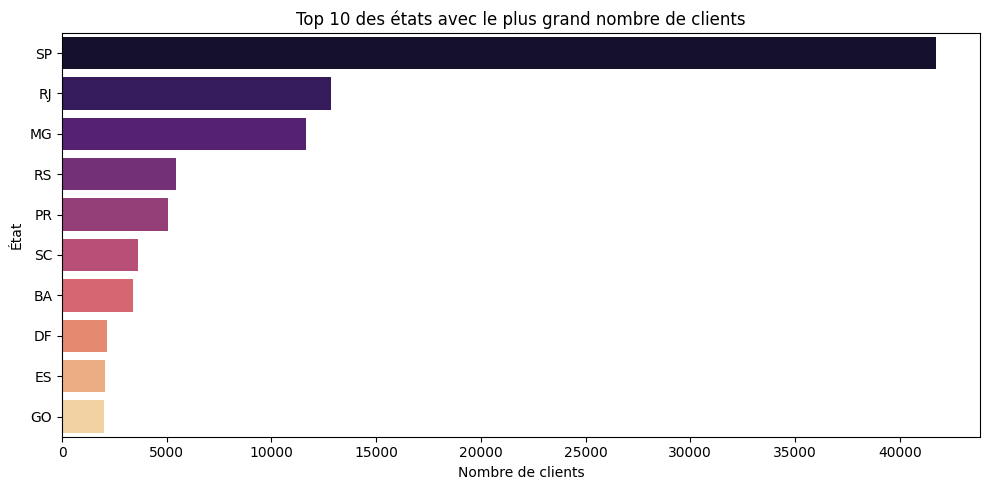

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculer le nombre de clients par état et trier par ordre décroissant
state_counts = df['customer_state'].value_counts().head(10).reset_index()
state_counts.columns = ['customer_state', 'count']

plt.figure(figsize=(10, 5))
sns.barplot(x='count', y='customer_state', data=state_counts, palette='magma', hue='customer_state', legend=False)
plt.xlabel('Nombre de clients')
plt.ylabel('État')
plt.title('Top 10 des états avec le plus grand nombre de clients')
plt.tight_layout()
plt.show()

In [ ]:
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_missing = order_items.isnull().sum()
print((order_missing/len(order_items)) * 100)
print(df.shape)
order_items = order_items.drop(columns=['product_id', 'seller_id', 'order_item_id'])
print(df.shape)
order_items.head()
#df = pd.merge(df, order_items, on='customer_id')

order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freight_value          0.0
dtype: float64
(99441, 3)
(99441, 3)


,order_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-13 13:57:51,199.90,18.14


In [ ]:
order_items['net_price'] = order_items['price'] - order_items['freight_value']
order_items = order_items.drop(columns=['order_id', 'shipping_limit_date'])

In [ ]:
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
reviews_missing = reviews.isnull().sum()
print((reviews_missing/len(reviews)) * 100)
print(reviews.shape)
reviews = reviews.drop(columns=['review_id', 'order_id'])
print("Dimension avant la suppréssion des valeurs manquantes:", reviews.shape)
reviews = reviews.dropna()
print("Dimension après la suppréssion des valeurs manquantes:", reviews.shape)
print(reviews.shape)
reviews.head()

review_id                   0.000000
order_id                    0.000000
review_score                0.000000
review_comment_title       88.341530
review_comment_message     58.702532
review_creation_date        0.000000
review_answer_timestamp     0.000000
dtype: float64
(99224, 7)
Dimension avant la suppréssion des valeurs manquantes: (99224, 5)
Dimension après la suppréssion des valeurs manquantes: (9839, 5)
(9839, 5)


,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
9,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22 00:00:00,2018-05-23 16:45:47
15,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes...",2018-05-23 00:00:00,2018-05-24 03:00:01
19,1,Não chegou meu produto,Péssimo,2018-08-15 00:00:00,2018-08-15 04:10:37
22,5,Ótimo,Loja nota 10,2018-07-10 00:00:00,2018-07-11 14:10:25
34,4,Muito bom.,Recebi exatamente o que esperava. As demais en...,2018-06-07 00:00:00,2018-06-09 18:44:02


In [ ]:
products = pd.read_csv("olist_products_dataset.csv")
products_missing = products.isnull().sum()
print((products_missing/len(products)) * 100)
print(products.shape)
products = products.dropna()
print(products.shape)
products.head()

product_id                    0.000000
product_category_name         1.851234
product_name_lenght           1.851234
product_description_lenght    1.851234
product_photos_qty            1.851234
product_weight_g              0.006070
product_length_cm             0.006070
product_height_cm             0.006070
product_width_cm              0.006070
dtype: float64
(32951, 9)
(32340, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
full_df= df.join([reviews, products], how="inner")
print(full_df.shape)
full_df = full_df.drop(columns=['product_id'])
full_df.head()

(3286, 17)


,customer_id,customer_city,customer_state,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9,4b7139f34592b3a31687243a302fa75b,belo horizonte,MG,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22 00:00:00,2018-05-23 16:45:47,brinquedos,36.0,1156.0,1.0,600.0,17.0,10.0,12.0
15,206f3129c0e4d7d0b9550426023f0a08,piracicaba,SP,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes...",2018-05-23 00:00:00,2018-05-24 03:00:01,esporte_lazer,22.0,3021.0,1.0,800.0,16.0,2.0,11.0
19,49d0ea0986edde72da777f15456a0ee0,pacaja,PA,1,Não chegou meu produto,Péssimo,2018-08-15 00:00:00,2018-08-15 04:10:37,cama_mesa_banho,52.0,206.0,1.0,500.0,16.0,10.0,16.0
22,2938121a40a20953c43caa8c98787fcb,sao paulo,SP,5,Ótimo,Loja nota 10,2018-07-10 00:00:00,2018-07-11 14:10:25,beleza_saude,58.0,1987.0,3.0,75.0,21.0,7.0,13.0
34,469634941c27cd844170935a3cf60b95,curitiba,PR,4,Muito bom.,Recebi exatamente o que esperava. As demais en...,2018-06-07 00:00:00,2018-06-09 18:44:02,esporte_lazer,50.0,699.0,4.0,1388.0,34.0,9.0,31.0


In [ ]:
full_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3286 entries, 9 to 32948
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 3286 non-null   object 
 1   customer_city               3286 non-null   object 
 2   customer_state              3286 non-null   object 
 3   review_score                3286 non-null   int64  
 4   review_comment_title        3286 non-null   object 
 5   review_comment_message      3286 non-null   object 
 6   review_creation_date        3286 non-null   object 
 7   review_answer_timestamp     3286 non-null   object 
 8   product_category_name       3286 non-null   object 
 9   product_name_lenght         3286 non-null   float64
 10  product_description_lenght  3286 non-null   float64
 11  product_photos_qty          3286 non-null   float64
 12  product_weight_g            3286 non-null   float64
 13  product_length_cm           3286 non-

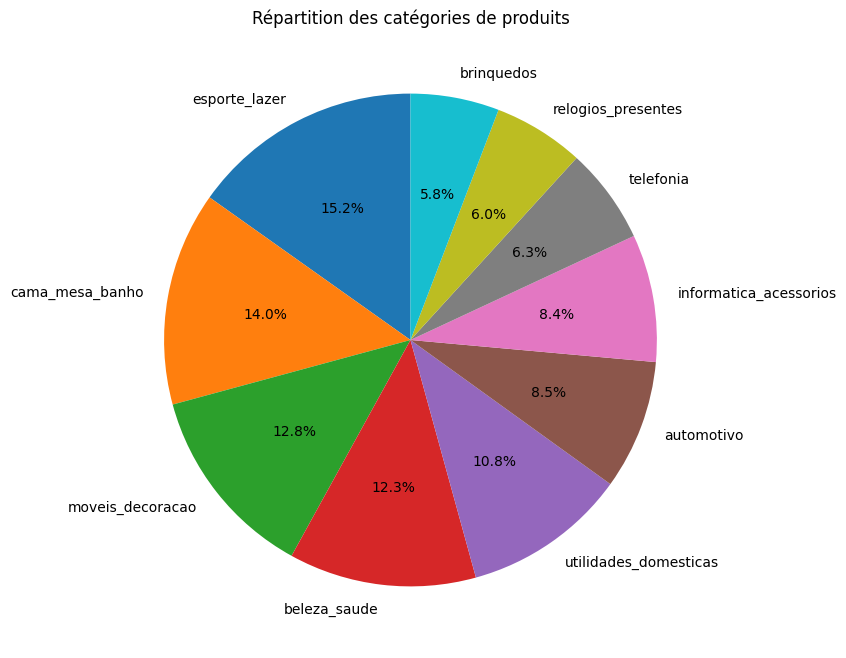

In [ ]:
product_dist = full_df['product_category_name'].value_counts().head(10).reset_index()
product_dist.columns = ['product_category_name', 'count']
plt.figure(figsize=(15, 8))
plt.pie(product_dist['count'], labels=product_dist['product_category_name'], autopct='%1.1f%%', startangle=90)
plt.title('Répartition des catégories de produits')
plt.show()

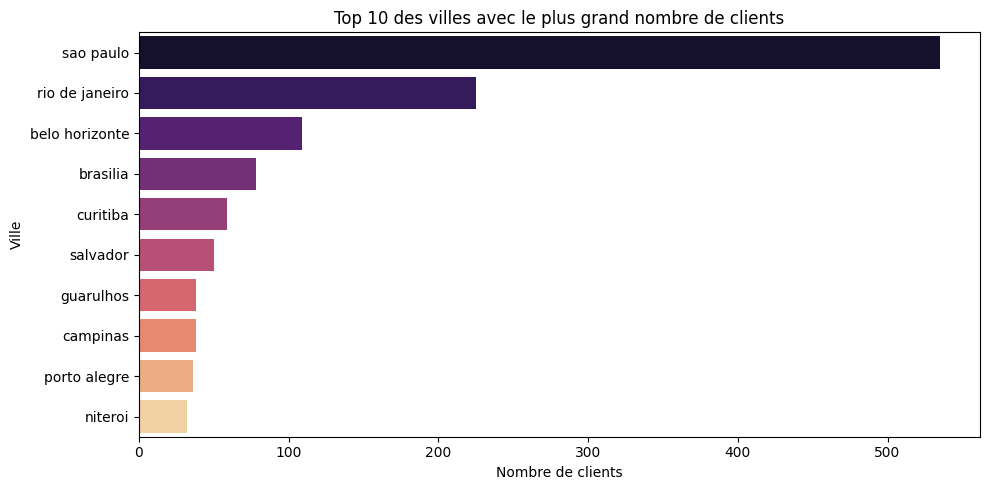

In [ ]:
top_cities = full_df['customer_city'].value_counts().head(10).reset_index()
top_cities.columns = ['customer_city', 'count']
plt.figure(figsize=(10, 5))
sns.barplot(x='count', y='customer_city', data=top_cities, palette='magma', hue='customer_city', legend=False)
plt.xlabel('Nombre de clients')
plt.ylabel('Ville')
plt.title('Top 10 des villes avec le plus grand nombre de clients')
plt.tight_layout()
plt.show()

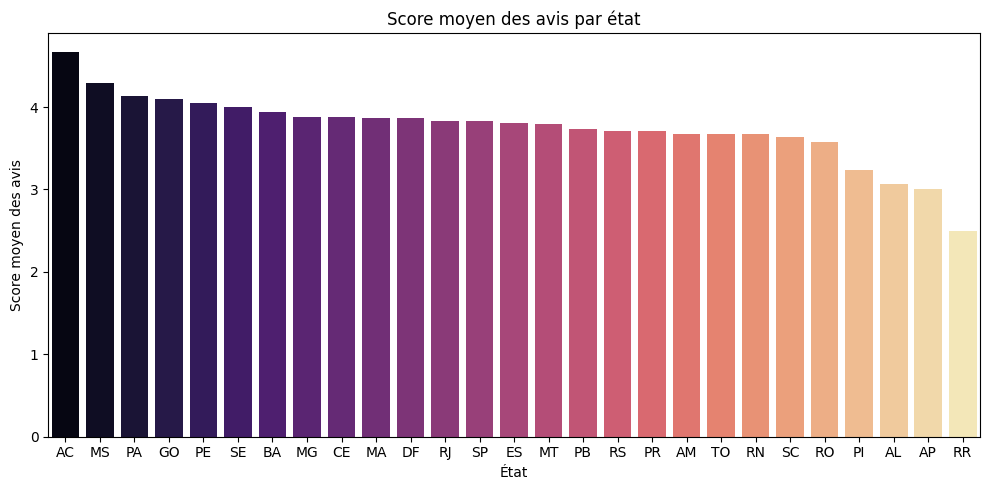

In [ ]:
state_review = full_df.groupby('customer_state')['review_score'].mean().sort_values(ascending=False).reset_index()
state_review.columns = ['customer_state', 'review_score']
plt.figure(figsize=(10, 5))
sns.barplot(x='customer_state', y='review_score', data=state_review, palette='magma', hue='customer_state', legend=False)
plt.xlabel('État')
plt.ylabel('Score moyen des avis')
plt.title('Score moyen des avis par état')
plt.tight_layout()
plt.show()

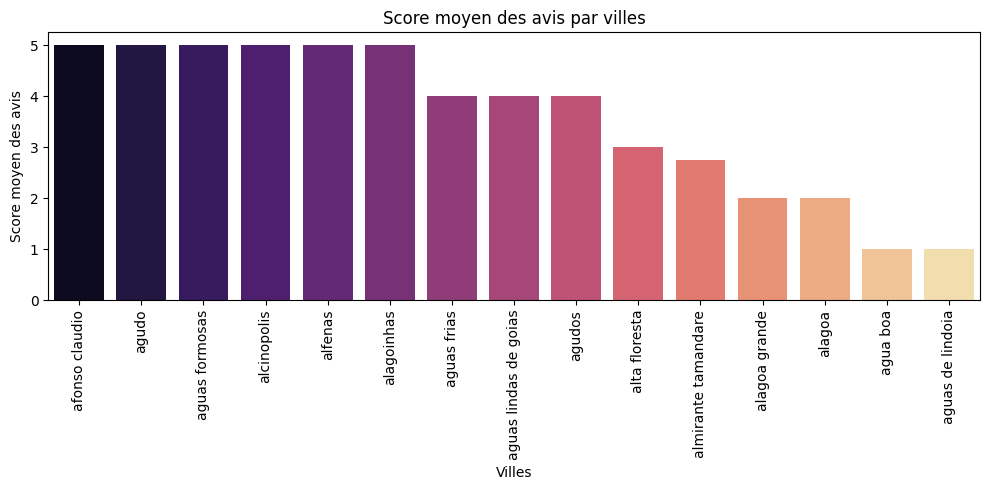

In [ ]:
city_review = full_df.groupby('customer_city')['review_score'].mean().head(15).sort_values(ascending=False).reset_index()
state_review.columns = ['customer_city', 'review_score']
plt.figure(figsize=(10, 5))
sns.barplot(x='customer_city', y='review_score', data=city_review, palette='magma', hue='customer_city', legend=False)
plt.xlabel('Villes')
plt.xticks(rotation=90)
plt.ylabel('Score moyen des avis')
plt.title('Score moyen des avis par villes')
plt.tight_layout()
plt.show()

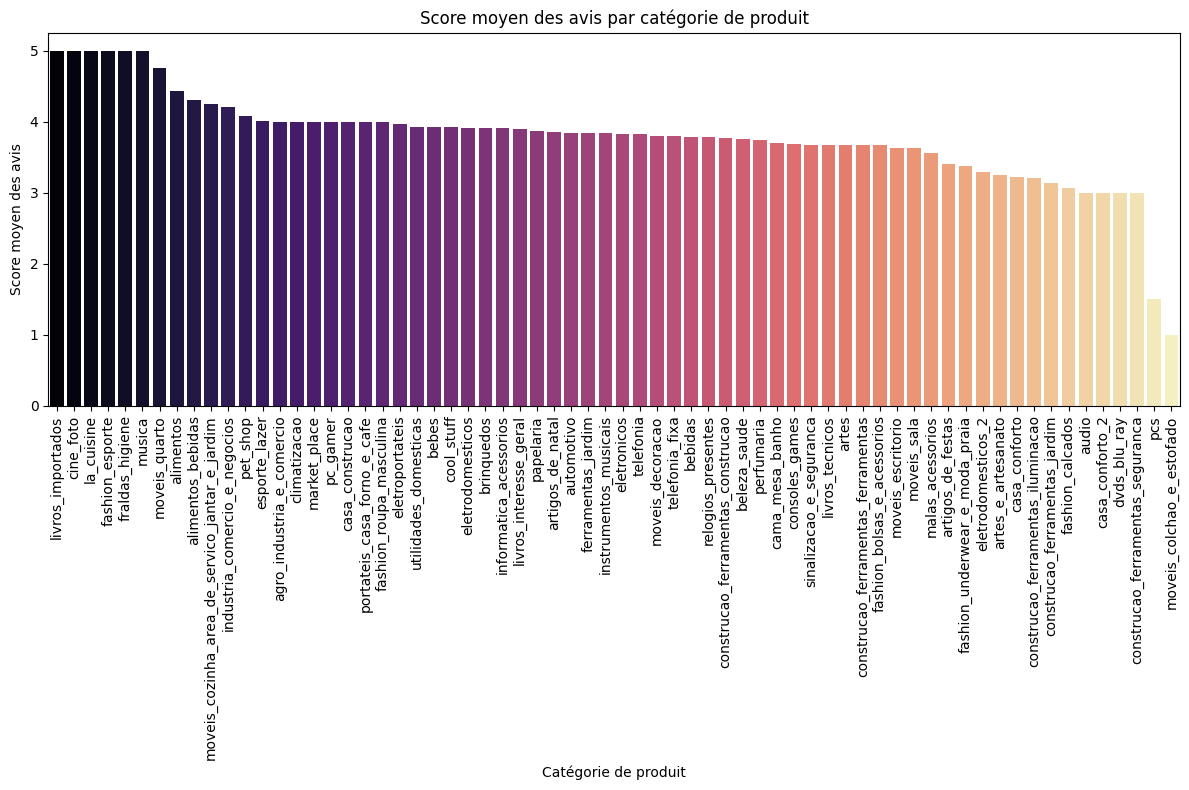

In [ ]:
product_review = full_df.groupby('product_category_name')['review_score'].mean().sort_values(ascending=False).reset_index()
plt.figure(figsize=(12, 8))
sns.barplot(x='product_category_name', y='review_score', data=product_review, palette='magma', hue='product_category_name', legend=False)
plt.xlabel('Catégorie de produit')
plt.xticks(rotation=90)
plt.ylabel('Score moyen des avis')
plt.title('Score moyen des avis par catégorie de produit')
plt.tight_layout()
plt.show()

In [ ]:
full_df['review_creation_date'] = pd.to_datetime(full_df['review_creation_date'])
full_df['review_answer_timestamp'] = pd.to_datetime(full_df['review_answer_timestamp'])
full_df['review_duration'] = full_df['review_answer_timestamp'] - full_df['review_creation_date']
full_df['review_duration'] = full_df['review_duration'].dt.days
full_df.head()

,customer_id,customer_city,customer_state,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,review_duration
9,4b7139f34592b3a31687243a302fa75b,belo horizonte,MG,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22,2018-05-23 16:45:47,brinquedos,36.0,1156.0,1.0,600.0,17.0,10.0,12.0,1
15,206f3129c0e4d7d0b9550426023f0a08,piracicaba,SP,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes...",2018-05-23,2018-05-24 03:00:01,esporte_lazer,22.0,3021.0,1.0,800.0,16.0,2.0,11.0,1
19,49d0ea0986edde72da777f15456a0ee0,pacaja,PA,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,cama_mesa_banho,52.0,206.0,1.0,500.0,16.0,10.0,16.0,0
22,2938121a40a20953c43caa8c98787fcb,sao paulo,SP,5,Ótimo,Loja nota 10,2018-07-10,2018-07-11 14:10:25,beleza_saude,58.0,1987.0,3.0,75.0,21.0,7.0,13.0,1
34,469634941c27cd844170935a3cf60b95,curitiba,PR,4,Muito bom.,Recebi exatamente o que esperava. As demais en...,2018-06-07,2018-06-09 18:44:02,esporte_lazer,50.0,699.0,4.0,1388.0,34.0,9.0,31.0,2


In [ ]:
timedelta_duration = full_df['review_answer_timestamp'] - full_df['review_creation_date']
full_df['hour_duration'] = timedelta_duration.dt.total_seconds() / 3600
full_df.head()

,customer_id,customer_city,customer_state,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,review_duration,hour_duration
9,4b7139f34592b3a31687243a302fa75b,belo horizonte,MG,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22,2018-05-23 16:45:47,brinquedos,36.0,1156.0,1.0,600.0,17.0,10.0,12.0,1,40.763056
15,206f3129c0e4d7d0b9550426023f0a08,piracicaba,SP,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes...",2018-05-23,2018-05-24 03:00:01,esporte_lazer,22.0,3021.0,1.0,800.0,16.0,2.0,11.0,1,27.000278
19,49d0ea0986edde72da777f15456a0ee0,pacaja,PA,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,cama_mesa_banho,52.0,206.0,1.0,500.0,16.0,10.0,16.0,0,4.176944
22,2938121a40a20953c43caa8c98787fcb,sao paulo,SP,5,Ótimo,Loja nota 10,2018-07-10,2018-07-11 14:10:25,beleza_saude,58.0,1987.0,3.0,75.0,21.0,7.0,13.0,1,38.173611
34,469634941c27cd844170935a3cf60b95,curitiba,PR,4,Muito bom.,Recebi exatamente o que esperava. As demais en...,2018-06-07,2018-06-09 18:44:02,esporte_lazer,50.0,699.0,4.0,1388.0,34.0,9.0,31.0,2,66.733889


/tmp/ipykernel_1091/2101533356.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='product_category_name', y='hour_duration', data=product_rev_duration, palette='magma')


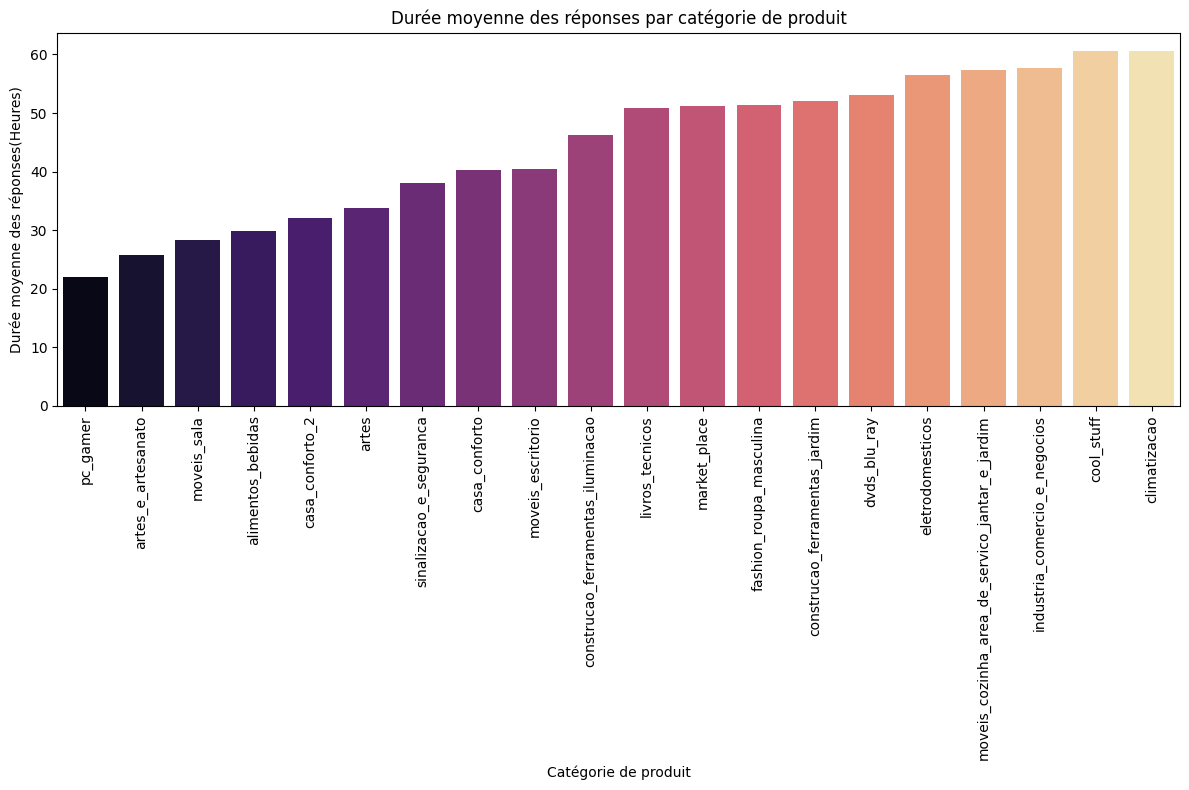

In [ ]:
product_rev_duration = full_df.groupby('product_category_name')['hour_duration'].mean().sort_values(ascending=True).head(20).reset_index()
plt.figure(figsize=(12, 8))
sns.barplot(x='product_category_name', y='hour_duration', data=product_rev_duration, palette='magma')
plt.xlabel('Catégorie de produit')
plt.xticks(rotation=90)
plt.ylabel('Durée moyenne des réponses(Heures)')
plt.title('Durée moyenne des réponses par catégorie de produit')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1091/92075989.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='product_category_name', y='net_price', data=product_price, palette='magma')


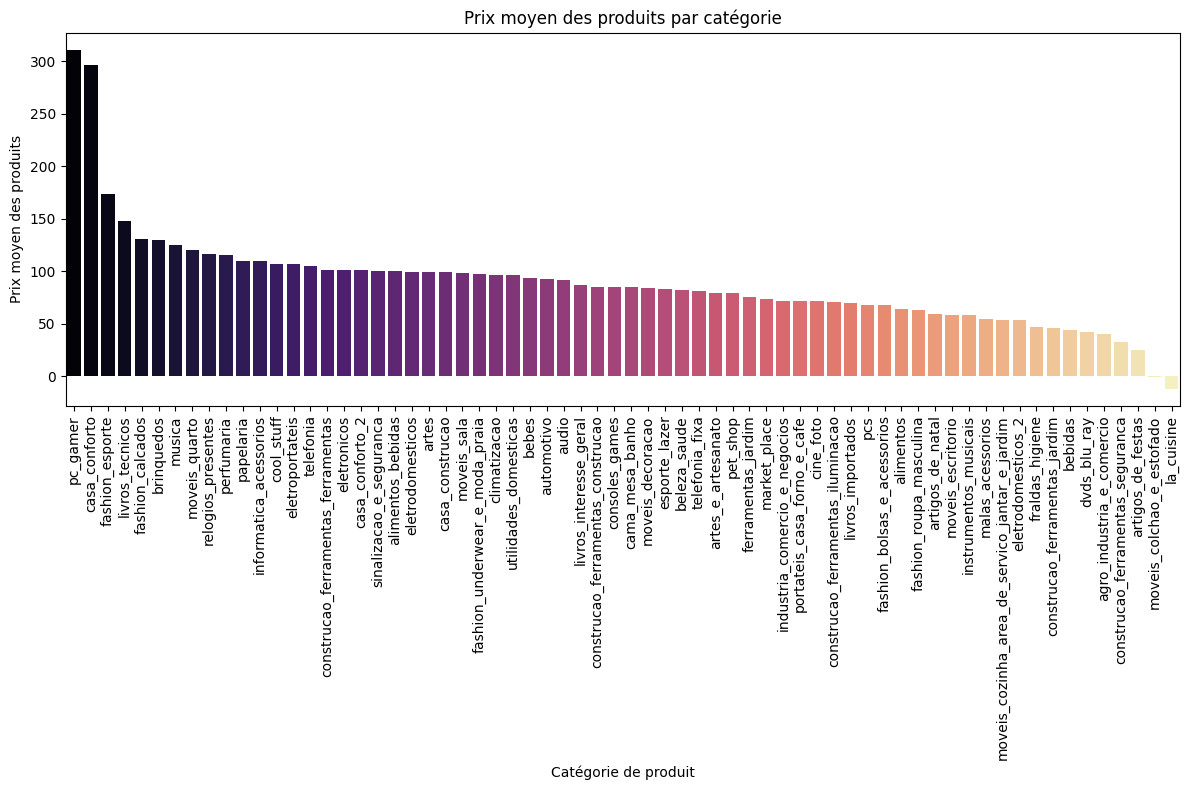

In [ ]:
full_df = full_df.join(order_items, how="inner")
product_price = full_df.groupby('product_category_name')['net_price'].mean().sort_values(ascending=False).reset_index()
plt.figure(figsize=(12, 8))
sns.barplot(x='product_category_name', y='net_price', data=product_price, palette='magma')
plt.xlabel('Catégorie de produit')
plt.xticks(rotation=90)
plt.ylabel('Prix moyen des produits')
plt.title('Prix moyen des produits par catégorie')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import numpy as np

# 1. Préparation de la cible (Classification binaire : 1 si score >= 4, sinon 0)
full_df['is_satisfied'] = (full_df['review_score'] >= 4).astype(int)

# 2. Sélection des fonctionnalités (Features)
features = ['hour_duration', 'net_price', 'product_category_name', 'customer_state', 'product_photos_qty',
            'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'freight_value']
X = full_df[features].copy()
y = full_df['is_satisfied']

# Convertir les variables catégorielles en variables indicatrices (One-Hot Encoding)
X = pd.get_dummies(X, columns=['product_category_name', 'customer_state'], drop_first=True)

# Gérer les valeurs manquantes s'il y en a
X = X.fillna(X.median())

# 3. Division du dataset (Train / Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Entraînement du modèle RandomForest
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

# 5. Prédictions
y_pred = model.predict(X_test)

# 6. Évaluation du modèle
print("=== EXACTITUDE (ACCURACY) ===")
print(f"{accuracy_score(y_test, y_pred):.4f}\n")

print("=== RAPPORT DE CLASSIFICATION ===")
print(classification_report(y_test, y_pred))

# 7. Importance des fonctionnalités (Top 10)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

print("=== TOP 10 DES FEATURES LES PLUS IMPORTANTES ===")
for f in range(min(10, X.shape[1])):
    print(f"{f + 1}. {X.columns[indices[f]]} ({importances[indices[f]]:.4f})")

=== EXACTITUDE (ACCURACY) ===
0.6991

=== RAPPORT DE CLASSIFICATION ===
              precision    recall  f1-score   support

           0       0.51      0.09      0.15       199
           1       0.71      0.96      0.82       459

    accuracy                           0.70       658
   macro avg       0.61      0.53      0.49       658
weighted avg       0.65      0.70      0.62       658

=== TOP 10 DES FEATURES LES PLUS IMPORTANTES ===
1. hour_duration (0.1303)
2. net_price (0.1086)
3. freight_value (0.1086)
4. product_weight_g (0.0934)
5. product_height_cm (0.0853)
6. product_width_cm (0.0807)
7. product_length_cm (0.0780)
8. product_photos_qty (0.0434)
9. customer_state_SP (0.0178)
10. customer_state_RJ (0.0125)


In [1]:
readme_content = """Analyse de satisfaction client Olist. Nettoyage et fusion des données clients, avis, produits et commandes. Visualisation de la répartition géographique, des notes et des prix par catégorie. Modélisation prédictive de la satisfaction client via un algorithme Random Forest. Les facteurs clés identifiés sont le délai de réponse aux avis, le prix net des articles et les frais de port."""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print(f"Fichier README.md créé avec succès ({len(readme_content)} caractères).")

Fichier README.md créé avec succès (384 caractères).
